# Unemployment Analysis: COVID-19 Impact and Insights

## 1. Project Introduction

### Project Overview

The COVID-19 pandemic had a significant impact on economies and labour markets worldwide.

This notebook focuses on investigating changes in unemployment rates in India during the COVID-19 period using the cleaned datasets prepared in the first notebook.

The analysis aims to identify unemployment trends before, during, and after the beginning of the pandemic, while examining regional differences and possible seasonal patterns.

### Project Objectives

The main objectives are:

- Analyze unemployment trends before and during the COVID-19 period.
- Compare unemployment rates across different periods.
- Investigate the impact of the pandemic on different Indian regions.
- Identify significant changes in unemployment rates.
- Explore possible seasonal patterns, where supported by the available data.
- Develop insights and recommendations based on the findings.

### Project Methodology

The analysis follows these steps:

1. Load the cleaned datasets.
2. Prepare the data for temporal analysis.
3. Define pre-COVID and COVID-19 periods.
4. Compare unemployment rates across periods.
5. Analyze regional variations.
6. Investigate temporal patterns.
7. Develop economic and social policy insights.
8. Present the final conclusions.

### Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Dataset Description

This notebook uses the two cleaned CSV datasets generated in the first notebook.

The datasets contain unemployment rates, estimated employment, labour participation rates, and geographical information covering different periods between 2019 and 2020.

## 2. Importing Libraries

In this section, we import the libraries required for temporal analysis, statistical calculations, and data visualization.

The following libraries will be used:

- **Pandas:** for data manipulation and time-based analysis.
- **NumPy:** for numerical calculations.
- **Matplotlib:** for creating charts and visualizing trends.
- **Seaborn:** for statistical visualizations.
- **Warnings:** to manage unnecessary warning messages.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warning management
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the Cleaned Datasets

In this section, we load the cleaned datasets generated during the Exploratory Data Analysis.

We will use both datasets to investigate unemployment trends during the COVID-19 period.

The datasets will be loaded separately to preserve their original structures and avoid introducing duplicate observations.

In [2]:
# Load cleaned datasets
df_india = pd.read_csv("../data/unemployment_india_cleaned.csv")
df_upto_2020 = pd.read_csv("../data/unemployment_upto_2020_cleaned.csv")

# Convert Date columns to datetime
df_india["Date"] = pd.to_datetime(df_india["Date"])
df_upto_2020["Date"] = pd.to_datetime(df_upto_2020["Date"])

# Display dataset dimensions
print("Dataset 1 - Unemployment in India")
print("Shape:", df_india.shape)
display(df_india.head())

print("\nDataset 2 - Unemployment Rate up to November 2020")
print("Shape:", df_upto_2020.shape)
display(df_upto_2020.head())

Dataset 1 - Unemployment in India
Shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



Dataset 2 - Unemployment Rate up to November 2020
Shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74


## 4. Data Preparation

Before analyzing the impact of COVID-19, we need to prepare the datasets for temporal comparisons.

In this section, we will:

- Standardize the unemployment rate column name.
- Extract year and month information from the dates.
- Define the periods used for the COVID-19 analysis.
- Examine the distribution of observations across these periods.

These preparations will facilitate comparisons between unemployment rates before and during the pandemic.

### 4.1 Standardizing and Extracting Date Information

In this step, we standardize the unemployment rate column names across both datasets and extract additional time-related variables.

We will create:
- `Year`: the year of each observation.
- `Month`: the month number.
- `Month_Name`: the month name.
- `Period`: a categorical variable distinguishing the pre-COVID period from the COVID-19 period.

For this analysis, March 2020 is used as the beginning of the COVID-19 period, while observations before March 2020 are classified as pre-COVID.

This classification is an analytical convention used to compare the observed periods. It does not imply that the pandemic began on exactly the same date in every region.

In [3]:
# Standardize unemployment rate column names
df_upto_2020.rename(
    columns={"Estimated Unemployment Rate (%)": "Estimated Unemployment Rate (%)"},
    inplace=True
)

# Extract time-related features from Dataset 1
for df in [df_india, df_upto_2020]:
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Month_Name"] = df["Date"].dt.strftime("%B")

    # Classify observations into pre-COVID and COVID periods
    df["Period"] = np.where(
        df["Date"] < pd.Timestamp("2020-03-01"),
        "Pre-COVID",
        "COVID-19"
    )

# Display the results
print("DATASET 1 - Prepared Data")
display(df_india[["Date", "Year", "Month", "Month_Name", "Period"]].head())

print("\nDATASET 2 - Prepared Data")
display(df_upto_2020[["Date", "Year", "Month", "Month_Name", "Period"]].head())

DATASET 1 - Prepared Data


,Date,Year,Month,Month_Name,Period
0,2019-05-31,2019,5,May,Pre-COVID
1,2019-06-30,2019,6,June,Pre-COVID
2,2019-07-31,2019,7,July,Pre-COVID
3,2019-08-31,2019,8,August,Pre-COVID
4,2019-09-30,2019,9,September,Pre-COVID



DATASET 2 - Prepared Data


,Date,Year,Month,Month_Name,Period
0,2020-01-31,2020,1,January,Pre-COVID
1,2020-02-29,2020,2,February,Pre-COVID
2,2020-03-31,2020,3,March,COVID-19
3,2020-04-30,2020,4,April,COVID-19
4,2020-05-31,2020,5,May,COVID-19


### 4.2 Distribution of Observations by Period

In this section, we examine the number of observations available in each period.

This step helps us understand the temporal coverage of the datasets and determine whether there are enough observations to support meaningful comparisons between the pre-COVID and COVID-19 periods.

DATASET 1 - Observations by Period


,Number of Observations
Period,
Pre-COVID,536
COVID-19,204



DATASET 2 - Observations by Period


,Number of Observations
Period,
COVID-19,215
Pre-COVID,52


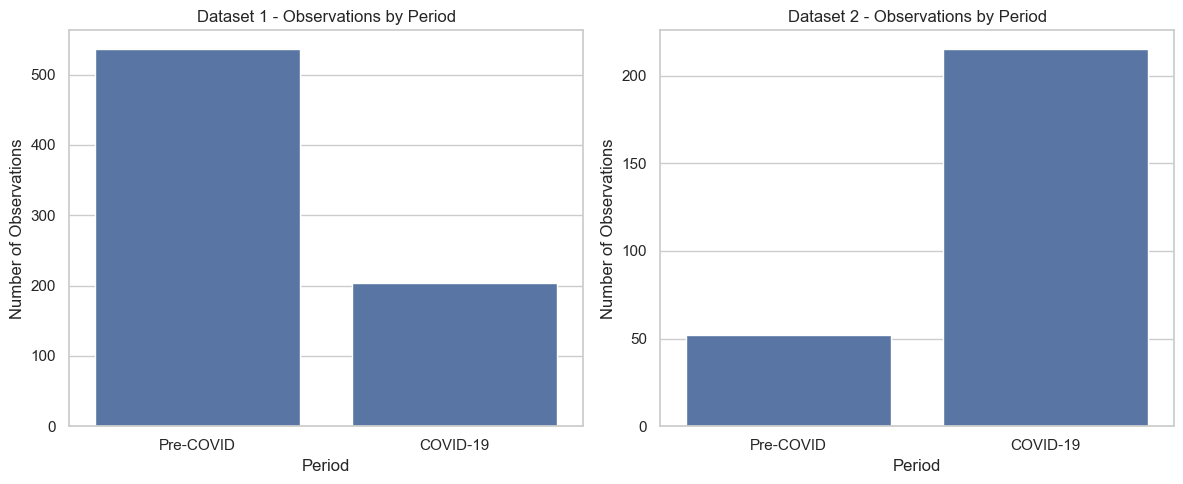

In [4]:
# Count observations by period in Dataset 1
period_counts_1 = df_india["Period"].value_counts()

# Count observations by period in Dataset 2
period_counts_2 = df_upto_2020["Period"].value_counts()

# Display results
print("DATASET 1 - Observations by Period")
display(period_counts_1.to_frame("Number of Observations"))

print("\nDATASET 2 - Observations by Period")
display(period_counts_2.to_frame("Number of Observations"))

# Visualize observation counts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df_india, x="Period", ax=axes[0])
axes[0].set_title("Dataset 1 - Observations by Period")
axes[0].set_xlabel("Period")
axes[0].set_ylabel("Number of Observations")

sns.countplot(data=df_upto_2020, x="Period", ax=axes[1])
axes[1].set_title("Dataset 2 - Observations by Period")
axes[1].set_xlabel("Period")
axes[1].set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()

### 4.3 Comparing Unemployment Rates Before and During COVID-19

In this section, we compare average unemployment rates between the pre-COVID and COVID-19 periods.

The analysis is performed separately for each dataset to preserve their different temporal coverage.

We will calculate:
- Average unemployment rate before COVID-19.
- Average unemployment rate during COVID-19.
- Absolute change in percentage points.
- Relative percentage change.

These comparisons will help quantify the observed changes in unemployment during the pandemic period.

In [5]:
# Function to calculate unemployment changes
def calculate_covid_impact(df):
    period_rates = (
        df.groupby("Period")["Estimated Unemployment Rate (%)"]
        .mean()
    )

    pre_covid = period_rates["Pre-COVID"]
    covid = period_rates["COVID-19"]

    absolute_change = covid - pre_covid
    percentage_change = (absolute_change / pre_covid) * 100

    return pd.Series({
        "Pre-COVID Average (%)": pre_covid,
        "COVID-19 Average (%)": covid,
        "Absolute Change (percentage points)": absolute_change,
        "Relative Change (%)": percentage_change
    })


# Calculate impact for each dataset separately
impact_1 = calculate_covid_impact(df_india)
impact_2 = calculate_covid_impact(df_upto_2020)

# Combine results into a comparison table
impact_comparison = pd.DataFrame({
    "Dataset 1": impact_1,
    "Dataset 2": impact_2
})

print("COVID-19 Unemployment Impact Comparison:")
display(impact_comparison.round(2))

COVID-19 Unemployment Impact Comparison:


,Dataset 1,Dataset 2
Pre-COVID Average (%),9.51,9.23
COVID-19 Average (%),17.77,12.96
Absolute Change (percentage points),8.26,3.73
Relative Change (%),86.91,40.43


### 4.4 Visualizing the COVID-19 Impact

In this section, we visualize the average unemployment rates before and during the COVID-19 period.

A grouped bar chart will allow us to compare the two periods across both datasets.

This visualization provides a clearer view of the observed changes in unemployment rates.

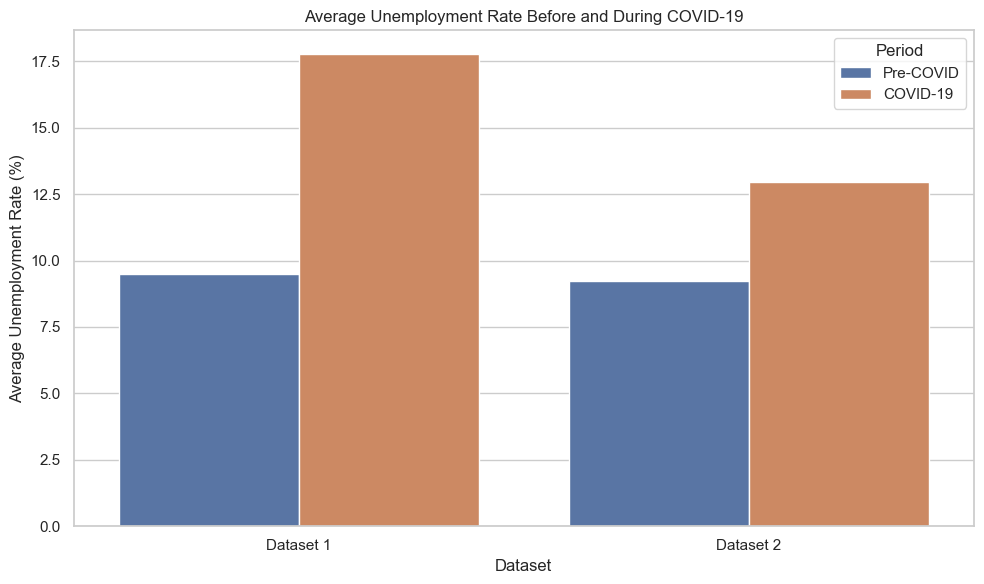

In [6]:
# Prepare comparison data
comparison_data = pd.DataFrame({
    "Dataset": ["Dataset 1", "Dataset 1", "Dataset 2", "Dataset 2"],
    "Period": ["Pre-COVID", "COVID-19", "Pre-COVID", "COVID-19"],
    "Unemployment Rate (%)": [
        impact_1["Pre-COVID Average (%)"],
        impact_1["COVID-19 Average (%)"],
        impact_2["Pre-COVID Average (%)"],
        impact_2["COVID-19 Average (%)"]
    ]
})

# Create grouped bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_data,
    x="Dataset",
    y="Unemployment Rate (%)",
    hue="Period"
)

plt.title("Average Unemployment Rate Before and During COVID-19")
plt.xlabel("Dataset")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

**Interpretation:**

The grouped bar chart highlights an increase in average unemployment rates during the COVID-19 period in both datasets.

In Dataset 1, the average unemployment rate increased from 9.51% to 17.77%.

In Dataset 2, it increased from 9.23% to 12.96%.

These results confirm that unemployment rates were higher during the observed COVID-19 period.

However, the differences in temporal coverage and geographical observations mean that the two datasets should be interpreted separately. The comparison is descriptive and does not establish a causal effect of the pandemic.

### 4.5 Regional Impact of COVID-19

In this section, we investigate how unemployment rates changed across different Indian regions.

For each region, we calculate:

- Average unemployment rate before COVID-19.
- Average unemployment rate during COVID-19.
- Absolute change in percentage points.

This analysis will help identify the regions that experienced the largest increases in unemployment.

The analysis will use Dataset 1, which provides observations across a longer pre-COVID period.

In [7]:
# Calculate average unemployment rate by region and period
regional_impact = (
    df_india
    .groupby(["Region", "Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
)

# Calculate the absolute change in percentage points
regional_impact["Absolute Change (pp)"] = (
    regional_impact["COVID-19"] - regional_impact["Pre-COVID"]
)

# Calculate the relative change in percentage
regional_impact["Relative Change (%)"] = (
    regional_impact["Absolute Change (pp)"]
    / regional_impact["Pre-COVID"]
) * 100

# Sort regions by absolute change
regional_impact = regional_impact.sort_values(
    "Absolute Change (pp)",
    ascending=False
)

# Display regional results
print("Regional COVID-19 Unemployment Impact:")
display(regional_impact.round(2))

Regional COVID-19 Unemployment Impact:


Period,COVID-19,Pre-COVID,Absolute Change (pp),Relative Change (%)
Region,,,,
Puducherry,38.96,1.59,37.36,2345.39
Tamil Nadu,25.40,2.84,22.57,795.60
Jharkhand,36.35,14.28,22.07,154.55
Bihar,31.63,13.83,17.80,128.67
Karnataka,15.28,3.23,12.05,372.41
Haryana,34.65,22.94,11.72,51.09
Kerala,17.95,6.99,10.96,156.74
Telangana,15.44,4.66,10.79,231.67
Madhya Pradesh,14.07,4.74,9.33,196.77


### 4.6 Most Affected Regions During COVID-19

In this section, we identify and visualize the ten regions with the largest increases in unemployment rates during the COVID-19 period.

The comparison is based on absolute changes expressed in percentage points.

This visualization highlights geographical disparities in the observed unemployment changes.

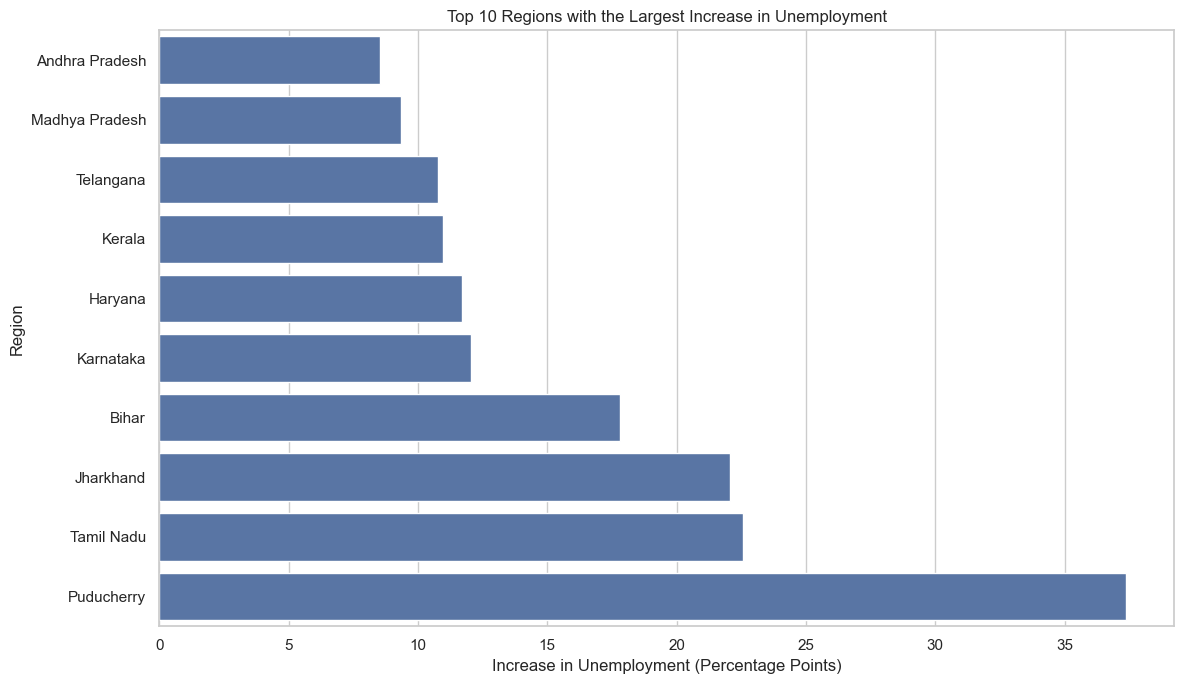

In [8]:
# Select the 10 regions with the largest increases
top_10_regions = (
    regional_impact
    .nlargest(10, "Absolute Change (pp)")
    .sort_values("Absolute Change (pp)", ascending=True)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_regions.reset_index(),
    x="Absolute Change (pp)",
    y="Region"
)

plt.title("Top 10 Regions with the Largest Increase in Unemployment")
plt.xlabel("Increase in Unemployment (Percentage Points)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

**Interpretation:**

The analysis identifies Puducherry as the region with the largest increase in unemployment, with an absolute change of 37.36 percentage points.

Tamil Nadu and Jharkhand follow, with increases of 22.57 and 22.07 percentage points, respectively.

Bihar and Karnataka also experienced substantial increases.

These findings highlight significant regional disparities in unemployment changes during the observed COVID-19 period.

The results are descriptive and should not be interpreted as proof that COVID-19 alone caused these changes.

### 4.7 Monthly Unemployment Trends During COVID-19

In this section, we analyze monthly unemployment rate variations during the COVID-19 period.

Using Dataset 2, we calculate the average unemployment rate for each month and visualize its evolution.

The objective is to identify the peak unemployment period and observe how unemployment changed over the following months.

Monthly Average Unemployment Rate During COVID-19:


,Unemployment Rate (%)
Month,
March,10.78
April,22.24
May,23.24
June,10.91
July,9.83
August,10.31
September,8.71
October,8.03


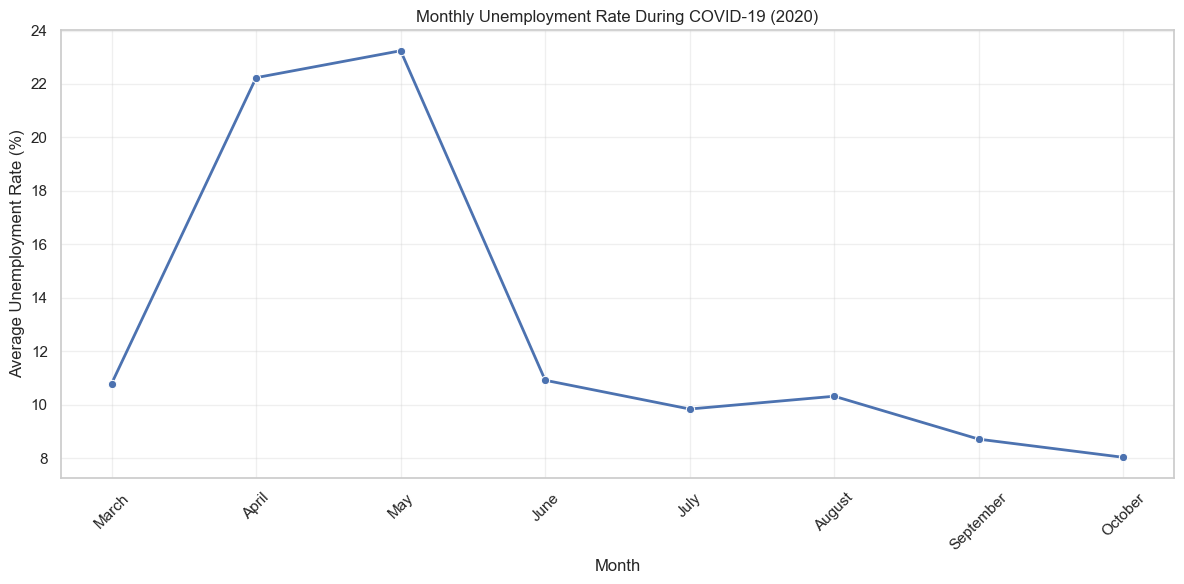

In [9]:
# Filter observations from the COVID-19 period
covid_data = df_upto_2020[
    df_upto_2020["Period"] == "COVID-19"
].copy()

# Calculate monthly average unemployment rate
covid_monthly = (
    covid_data
    .groupby("Month")["Estimated Unemployment Rate (%)"]
    .mean()
)

# Add month names
month_names = {
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October"
}

covid_monthly.index = covid_monthly.index.map(month_names)

# Display monthly averages
print("Monthly Average Unemployment Rate During COVID-19:")
display(covid_monthly.round(2).to_frame("Unemployment Rate (%)"))

# Visualize monthly trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=covid_monthly.index,
    y=covid_monthly.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Rate During COVID-19 (2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:**

The monthly analysis reveals significant changes in unemployment rates during the COVID-19 period.

The average unemployment rate increased sharply from 10.78% in March 2020 to 22.24% in April, reaching its highest level of 23.24% in May 2020.

A substantial decrease occurred in June 2020, when the rate fell to 10.91%.

Between July and October, unemployment generally declined, reaching 8.03% in October 2020.

These findings suggest that the strongest observed unemployment disruption occurred during April and May 2020, followed by a gradual improvement in the subsequent months.

However, this descriptive analysis does not establish that the pandemic was the only cause of these changes.

### 4.8 Rural vs Urban Impact During COVID-19

In this section, we compare unemployment rates between rural and urban areas during the COVID-19 period.

Using Dataset 1, we calculate the average unemployment rate for each area before and during the pandemic.

The objective is to identify differences in unemployment patterns between rural and urban labour markets.

In [10]:
# Calculate average unemployment rate by area and period
area_impact = (
    df_india
    .groupby(["Area", "Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
)

# Calculate absolute change in percentage points
area_impact["Absolute Change (pp)"] = (
    area_impact["COVID-19"] - area_impact["Pre-COVID"]
)

# Calculate relative change
area_impact["Relative Change (%)"] = (
    area_impact["Absolute Change (pp)"]
    / area_impact["Pre-COVID"]
) * 100

# Display results
print("Rural vs Urban Unemployment Impact:")
display(area_impact.round(2))

Rural vs Urban Unemployment Impact:


Period,COVID-19,Pre-COVID,Absolute Change (pp),Relative Change (%)
Area,,,,
Rural,16.18,8.09,8.09,99.90
Urban,19.28,10.84,8.43,77.79


#### Rural vs Urban Unemployment Comparison

The following visualization compares average unemployment rates in rural and urban areas before and during COVID-19.

A grouped bar chart is used to highlight differences between the two geographical categories.

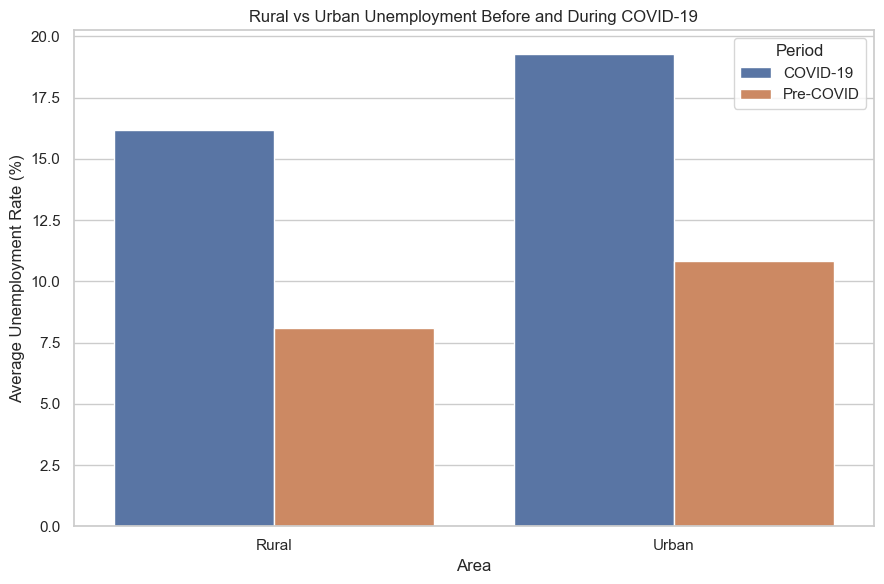

In [11]:
# Prepare data for visualization
area_comparison = (
    df_india
    .groupby(["Area", "Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

# Create grouped bar chart
plt.figure(figsize=(9, 6))

sns.barplot(
    data=area_comparison,
    x="Area",
    y="Estimated Unemployment Rate (%)",
    hue="Period"
)

plt.title("Rural vs Urban Unemployment Before and During COVID-19")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

**Interpretation:**

The comparison reveals an increase in unemployment rates in both rural and urban areas during the COVID-19 period.

In rural areas, the average unemployment rate increased from approximately 8.06% to 16.12%.

In urban areas, it increased from approximately 10.78% to 19.23%.

Urban areas recorded higher average unemployment rates in both periods.

These findings suggest that both rural and urban labour markets experienced substantial changes during the observed pandemic period, although the unemployment levels differed between the two areas.

This analysis is descriptive and does not establish a direct causal relationship between COVID-19 and unemployment.

## 5. Policy Insights and Recommendations

Based on the exploratory analysis and COVID-19 impact assessment, several economic and social insights can be identified.

### 5.1 Regional Employment Support

Regions such as Puducherry, Tamil Nadu, Jharkhand, and Bihar experienced particularly large increases in unemployment.

Targeted employment support programs could help regions facing stronger labour market disruptions.

### 5.2 Urban and Rural Employment Policies

Both rural and urban areas experienced increases in unemployment.

Urban employment initiatives could focus on supporting businesses and workers in vulnerable sectors, while rural programs could strengthen agricultural and non-agricultural employment opportunities.

### 5.3 Support for Vulnerable Workers

Temporary financial assistance, vocational training, and reskilling programs could help workers affected by economic disruptions.

### 5.4 Labour Market Monitoring

Regular monitoring of unemployment rates and labour participation indicators can help policymakers identify emerging difficulties and respond more quickly.

### 5.5 Data-Driven Decision Making

Regional and temporal unemployment analysis can support the design of targeted employment policies rather than relying on uniform measures across all regions.

## 6. Final Conclusion

This project investigated unemployment trends in India and explored the potential impact of the COVID-19 pandemic using two unemployment datasets.

The analysis revealed several important findings:

1. **Increase in Unemployment:** Both datasets showed higher average unemployment rates during the observed COVID-19 period compared with the pre-COVID period.

2. **Peak During the Pandemic:** The monthly analysis identified May 2020 as the month with the highest average unemployment rate in Dataset 2, reaching 23.24%.

3. **Regional Disparities:** Puducherry, Tamil Nadu, Jharkhand, and Bihar experienced particularly large increases in unemployment rates.

4. **Rural and Urban Differences:** Both rural and urban areas experienced substantial increases, while urban areas maintained higher average unemployment rates.

5. **Gradual Improvement:** The monthly analysis showed a decline in unemployment rates between June and October 2020.

### Recommendations

The findings highlight the importance of targeted employment support, regional development programs, vocational training, and continuous labour market monitoring.

Data-driven policies can help governments identify vulnerable regions and populations and respond more effectively to economic disruptions.

### Limitations

This analysis has several limitations:

- The datasets cover a relatively short period.
- The two datasets have different temporal coverage and geographical structures.
- Average unemployment rates are calculated without population-based weighting.
- Missing regional observations may affect comparisons.
- The analysis is descriptive and does not establish causal relationships.
- The available time series is insufficient to establish reliable recurring seasonal patterns.

### Final Remarks

The project demonstrates how Python and data analysis techniques can be used to explore unemployment trends, identify regional disparities, visualize economic changes, and generate insights that may support employment policy discussions.